# Bird Identification: Exploratory Data Analysis
**DS 4002 | Image classification | Southwest Virginia study area**

Purpose: understand the labeled image dataset before building a bird-species classifier. The primary future success measure is held-out classification accuracy. This notebook does not fit or tune a predictive model.

Run all cells in order. Inputs are in `Data`; generated tables and plots go to `Output`. The root is detected whether Jupyter starts in the project directory or in `Scripts`. All analysis works offline once the supplied ZIP is extracted.

Labels describe iNaturalist observations, not independently verified image annotations. Photos still require visual review. The regional definition is a bounding box intersected with Virginia, not an official county list.

## 1. Setup and portable file paths

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import hashlib
import json
import platform
import io

# Find the project by its input table, rather than assuming a personal directory.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'Data' / 'bird_images.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Start Jupyter in Bird_Identification or its Scripts folder.')
DATA = ROOT / 'Data'
OUTPUT = ROOT / 'Output'
OUTPUT.mkdir(exist_ok=True)
plt.rcParams.update({'font.size': 11, 'figure.dpi': 110})

# Save each plot to disk and also display it inside the notebook.
def save_plot(fig, filename):
    # Write complete PNG bytes and verify them before replacing the saved plot.
    buffer = io.BytesIO()
    fig.savefig(buffer, format='png', dpi=120, bbox_inches='tight')
    with Image.open(io.BytesIO(buffer.getvalue())) as check:
        check.load()
    (OUTPUT / filename).write_bytes(buffer.getvalue())
    plt.show()
    plt.close(fig)

print('Project:', ROOT.name)
print('Python:', platform.python_version())
print('pandas:', pd.__version__, '| NumPy:', np.__version__)

Project: Bird_Identification
Python: 3.12.14
pandas: 2.2.3 | NumPy: 2.3.5


## 2. Load the image manifest and establish the unit of observation

In [2]:
# Read identifiers as text so they are never rounded or treated as measurements.
id_columns = {c: 'string' for c in ['observation_id', 'photo_id', 'taxon_id', 'observer_id']}
df = pd.read_csv(DATA / 'bird_images.csv', dtype=id_columns)
df['date'] = pd.to_datetime(df['observed_on'], errors='coerce')
df['month_number'] = df['date'].dt.month
print(f'{len(df):,} images; {df.taxon_id.nunique()} species; {df.observer_id.nunique()} observers')
print('Observed date range:', df.date.min(), 'through', df.date.max())
print(df[['common_name', 'scientific_name', 'observed_on', 'split']].head().to_string(index=False))

# A modeling example is one photo from one observation, not one pixel or one observer.
assert df.observation_id.is_unique and df.photo_id.is_unique
assert df.sha256.is_unique
assert df['photo_license'].isin(['cc0', 'cc-by', 'cc-by-sa']).all()
assert df['split'].isin(['train', 'validation', 'test']).all()
assert df.groupby('observer_id')['split'].nunique().max() == 1
print('Passed identifier, exact-hash, photo-license, and observer-isolation checks.')

482 images; 12 species; 60 observers
Observed date range: 2010-05-06 00:00:00 through 2026-10-21 00:00:00
   common_name    scientific_name observed_on      split
American Robin Turdus migratorius  2026-05-03      train
American Robin Turdus migratorius  2026-07-28      train
American Robin Turdus migratorius  2026-04-25      train
American Robin Turdus migratorius  2025-08-03      train
American Robin Turdus migratorius  2020-06-16 validation
Passed identifier, exact-hash, photo-license, and observer-isolation checks.


## 3. Missing metadata, file integrity, and image dimensions

In [3]:
missing = df.isna().sum().rename('missing_count').to_frame()
missing['missing_percent'] = (100 * missing.missing_count / len(df)).round(2)
missing.to_csv(OUTPUT / 'missing_values.csv', index_label='feature')
print(missing.loc[missing.missing_count > 0].to_string())

# Verify that every referenced image exists, decodes, and matches its recorded bytes.
# Pixel hashes also find identical decoded pictures with different file metadata.
checks = []
for row in df.itertuples(index=False):
    path = ROOT / row.image_path
    try:
        with Image.open(path) as img:
            rgb = img.convert('RGB')
            pixel_hash = hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest()
            width, height = rgb.size
        sha_matches = hashlib.sha256(path.read_bytes()).hexdigest() == row.sha256
        status = 'ok' if sha_matches else 'hash_mismatch'
    except Exception as error:
        status, width, height, pixel_hash = type(error).__name__, None, None, None
    checks.append({'photo_id': row.photo_id, 'status': status,
                   'width': width, 'height': height, 'pixel_hash': pixel_hash})
checks = pd.DataFrame(checks)
checks.to_csv(OUTPUT / 'image_integrity.csv', index=False)
assert checks.status.eq('ok').all(), 'Investigate file-integrity failures before modeling.'
duplicates = checks[checks.pixel_hash.duplicated(keep=False)]
duplicates.to_csv(OUTPUT / 'pixel_duplicate_candidates.csv', index=False)
print('All referenced files decode and match their SHA-256 hashes.')
print('Rows in decoded-pixel duplicate groups:', len(duplicates))
print('These checks do not detect all near duplicates or verify bird identities.')

Empty DataFrame
Columns: [missing_count, missing_percent]
Index: []
All referenced files decode and match their SHA-256 hashes.
Rows in decoded-pixel duplicate groups: 0
These checks do not detect all near duplicates or verify bird identities.


## 4. How balanced are the species?
Question: are some classes much more common than others? Class counts affect how accuracy should be interpreted. A classifier predicting the most common species can score above uniform chance without using the image.

taxon_id          common_name  images  observers  share_percent
   11901         Barn Swallow      34         16           7.05
   12727       American Robin      48         21           9.96
   12942     Eastern Bluebird      60         22          12.45
  144814   Carolina Chickadee      35         10           7.26
  145310   American Goldfinch      38         16           7.88
   17008       Eastern Phoebe      42         17           8.71
    3454        Mourning Dove      41         19           8.51
    4956     Great Blue Heron      39         16           8.09
    8021        American Crow      27         12           5.60
    9083    Northern Cardinal      58         24          12.03
    9100         Song Sparrow      37         17           7.68
    9744 Red-winged Blackbird      23          7           4.77
Largest class share: 12.4%
Uniform random expectation for 12 classes: 8.3%


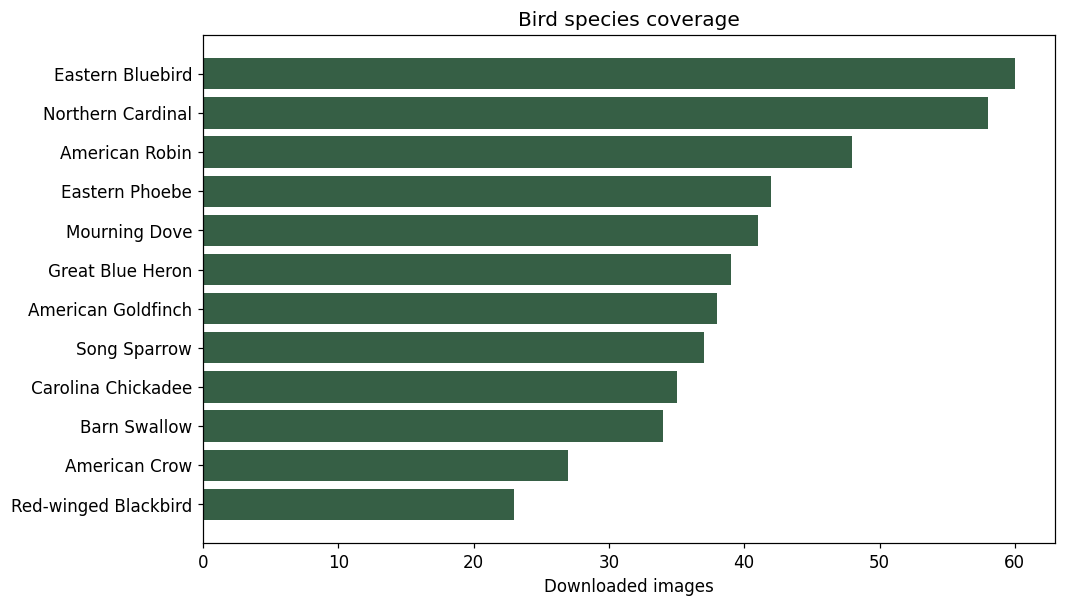

In [4]:
counts = df.groupby(['taxon_id', 'common_name']).size().rename('images').reset_index()
counts['observers'] = df.groupby('taxon_id').observer_id.nunique().reindex(counts.taxon_id).to_numpy()
counts['share_percent'] = (100 * counts.images / len(df)).round(2)
counts.to_csv(OUTPUT / 'species_summary.csv', index=False)
print(counts.to_string(index=False))
print(f'Largest class share: {100 * counts.images.max() / len(df):.1f}%')
print(f'Uniform random expectation for {len(counts)} classes: {100 / len(counts):.1f}%')
ordered = counts.sort_values('images')
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(ordered.common_name, ordered.images, color='#365f45')
ax.set(xlabel='Downloaded images', title='Bird species coverage')
save_plot(fig, '01_species_counts.png')

## 5. Are the proposed partitions usable for an accuracy comparison?
Photographer groups are kept together to reduce leakage from repeated styles and locations. Assignment uses only group/class counts, not model performance. Approximately 60/20/20 proportions are a target; inspect actual per-class coverage before freezing the analysis plan.

split                 train  validation  test
common_name                                  
American Crow            14           4     9
American Goldfinch       21           8     9
American Robin           20          16    12
Barn Swallow             20           5     9
Carolina Chickadee       21           6     8
Eastern Bluebird         34          11    15
Eastern Phoebe           27           5    10
Great Blue Heron         23           7     9
Mourning Dove            21          10    10
Northern Cardinal        36          10    12
Red-winged Blackbird     12           3     8
Song Sparrow             23           5     9
Total partition sizes: {'train': 272, 'test': 120, 'validation': 90}
Species with fewer than three examples in any partition: []


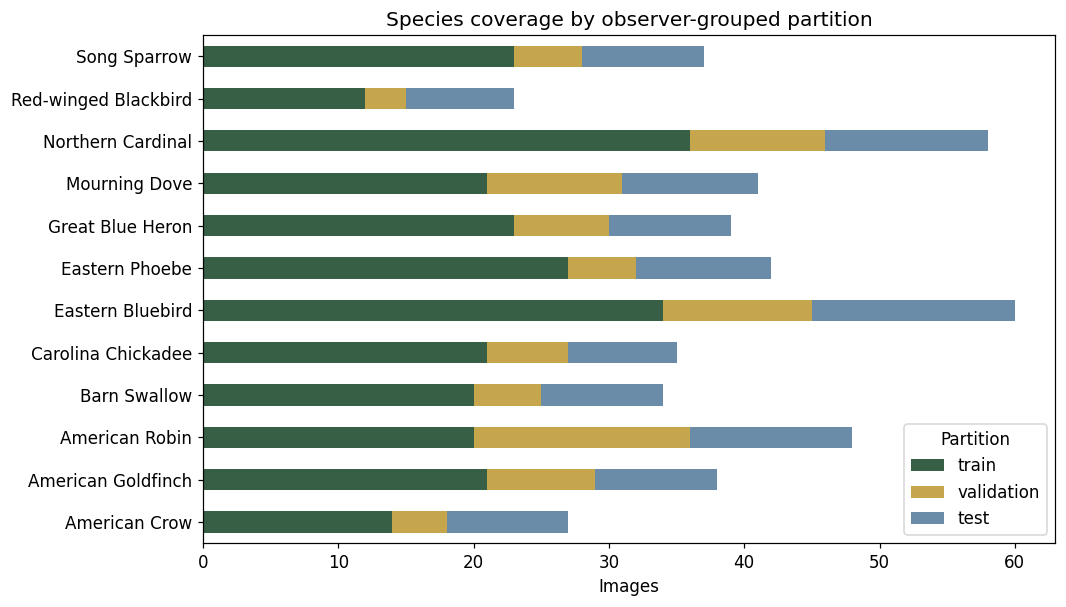

In [5]:
split_counts = pd.crosstab(df.common_name, df['split']).reindex(
    columns=['train', 'validation', 'test'], fill_value=0)
split_counts.to_csv(OUTPUT / 'species_split_counts.csv')
print(split_counts.to_string())
print('Total partition sizes:', df['split'].value_counts().to_dict())
print('Species with fewer than three examples in any partition:',
      split_counts.index[split_counts.min(axis=1) < 3].tolist())
fig, ax = plt.subplots(figsize=(10, 6))
split_counts.plot.barh(stacked=True, ax=ax, color=['#365f45', '#c5a64c', '#6a8ca8'])
ax.set(xlabel='Images', ylabel='', title='Species coverage by observer-grouped partition')
ax.legend(title='Partition', loc='lower right')
save_plot(fig, '02_split_coverage.png')

## 6. Observer concentration and seasonal sampling
Question: does this sample represent many independent photographers and all months? Observation counts are not bird abundance. They also reflect where and when people take and upload pictures.

Largest observer share: 19.7 %


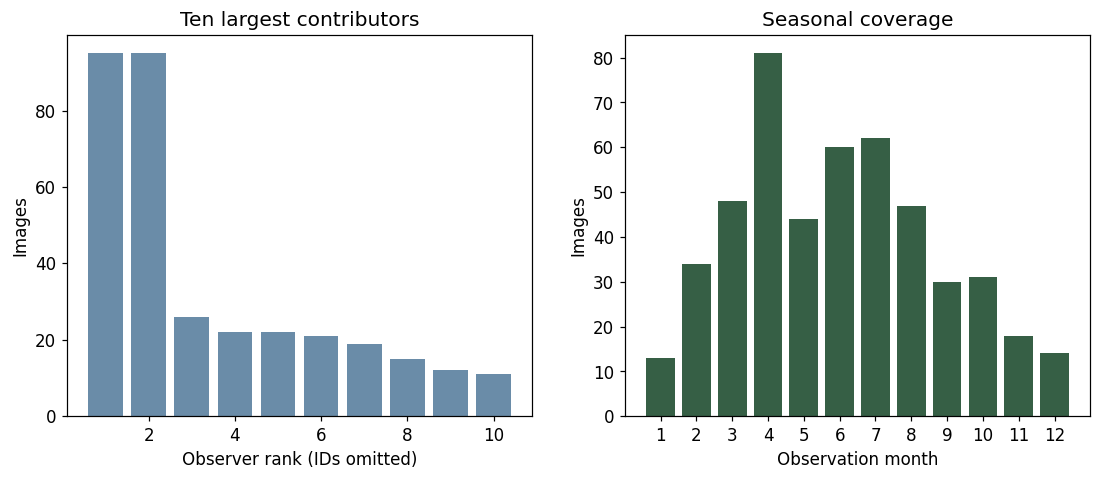

In [6]:
observer_counts = df.groupby('observer_id').size().sort_values(ascending=False)
observer_counts.rename('images').to_csv(OUTPUT / 'observer_counts.csv')
print('Largest observer share:', round(100 * observer_counts.iloc[0] / len(df), 1), '%')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(range(1, min(10, len(observer_counts)) + 1), observer_counts.head(10), color='#6a8ca8')
axes[0].set(xlabel='Observer rank (IDs omitted)', ylabel='Images', title='Ten largest contributors')
months = df.month_number.value_counts().reindex(range(1, 13), fill_value=0)
months.rename('images').to_csv(OUTPUT / 'month_counts.csv', index_label='month')
axes[1].bar(range(1, 13), months, color='#365f45')
axes[1].set(xlabel='Observation month', ylabel='Images', title='Seasonal coverage', xticks=range(1, 13))
save_plot(fig, '03_observers_and_months.png')

## 7. Image sizes and aspect ratios

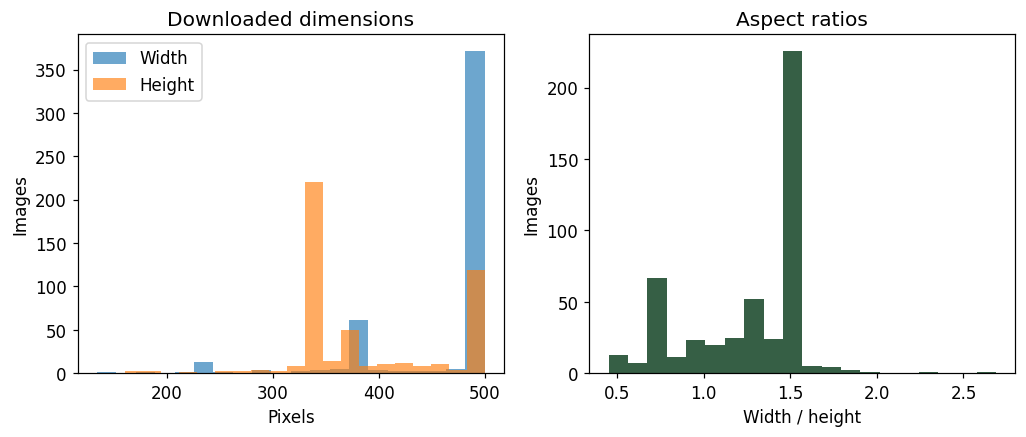

Use consistent image resizing for the model; keep originals for audit.
Image dimensions do not tell us how large the bird appears within the picture.


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df.width, bins=20, alpha=.65, label='Width')
axes[0].hist(df.height, bins=20, alpha=.65, label='Height')
axes[0].set(xlabel='Pixels', ylabel='Images', title='Downloaded dimensions')
axes[0].legend()
axes[1].hist(df.width / df.height, bins=20, color='#365f45')
axes[1].set(xlabel='Width / height', ylabel='Images', title='Aspect ratios')
save_plot(fig, '04_image_dimensions.png')
print('Use consistent image resizing for the model; keep originals for audit.')
print('Image dimensions do not tell us how large the bird appears within the picture.')

## 8. Labeled examples and a human review log
These are source labels, not newly verified identifications. Review for small birds, occlusion, multiple species, deceased birds, and images that do not clearly show the labeled subject. Do not remove difficult examples just because a model predicts them incorrectly. Record exclusion rules before evaluation.

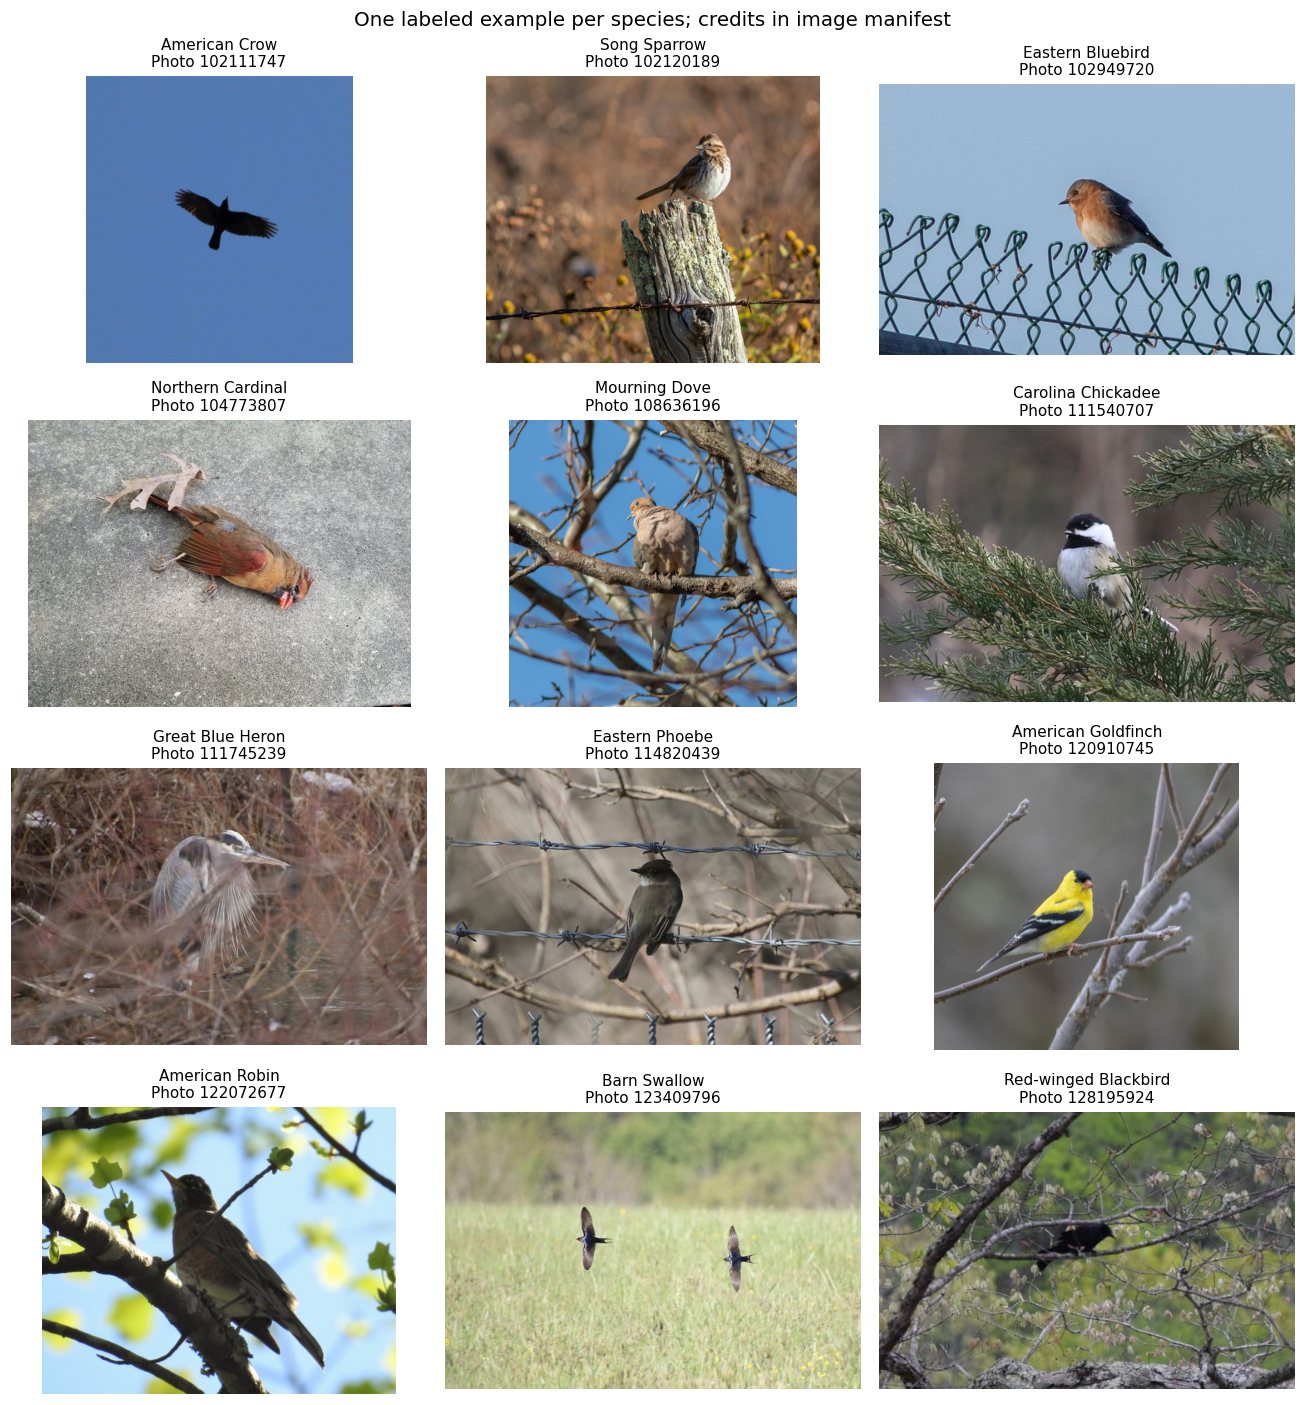

Quality review log: quality_review.csv
No automated species-label verification or manual exclusions were applied here.


In [8]:
examples = df.sort_values('photo_id').groupby('taxon_id', sort=True).head(1)
fig, axes = plt.subplots(4, 3, figsize=(12, 13))
for ax in axes.flat:
    ax.axis('off')
for ax, row in zip(axes.flat, examples.itertuples(index=False)):
    with Image.open(ROOT / row.image_path) as img:
        ax.imshow(img.convert('RGB'))
    ax.set_title(f'{row.common_name}\nPhoto {row.photo_id}', fontsize=10)
fig.suptitle('One labeled example per species; credits in image manifest', fontsize=13)
fig.tight_layout()
save_plot(fig, '05_example_images.png')

# Preserve manual decisions across reruns; do not overwrite an existing review file.
review_path = DATA / 'quality_review.csv'
if not review_path.exists():
    review = df[['photo_id', 'observation_id', 'common_name', 'image_path']].copy()
    review['review_status'] = 'pending'
    review['decision'] = ''
    review['reason'] = ''
    review.to_csv(review_path, index=False)
print('Quality review log:', review_path.name)
print('No automated species-label verification or manual exclusions were applied here.')

## 9. Save a concise EDA summary and plan the next stage
Future task: predict `taxon_id` from image pixels and report held-out accuracy. Common/scientific names, IDs, source paths, contributor IDs, and attribution are not image-model predictors. Do not expose species folder names or titles as model features. Fit preprocessing using training data and apply augmentation only to training images.

The planned comparison can be a simple image baseline versus a compact pretrained image classifier. The accuracy threshold must be agreed before final evaluation; this notebook does not claim that any target has been achieved. Keep species-level accuracy and a confusion matrix as supporting diagnostics.

In [9]:
summary = {
    'images': int(len(df)), 'species': int(df.taxon_id.nunique()),
    'observers': int(df.observer_id.nunique()),
    'split_counts': {str(k): int(v) for k, v in df['split'].value_counts().items()},
    'smallest_species_count': int(counts.images.min()),
    'largest_observer_share': float(observer_counts.iloc[0] / len(df)),
    'pixel_duplicate_rows': int(len(duplicates)),
    'all_files_valid': bool(checks.status.eq('ok').all()),
    'all_species_in_every_partition': bool((split_counts > 0).all().all()),
    'human_quality_review_complete': False,
    'model_fitted': False
}
(OUTPUT / 'eda_summary.json').write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

{
  "images": 482,
  "species": 12,
  "observers": 60,
  "split_counts": {
    "train": 272,
    "test": 120,
    "validation": 90
  },
  "smallest_species_count": 23,
  "largest_observer_share": 0.1970954356846473,
  "pixel_duplicate_rows": 0,
  "all_files_valid": true,
  "all_species_in_every_partition": true,
  "human_quality_review_complete": false,
  "model_fitted": false
}


## References
1. iNaturalist, “iNaturalist API.” https://api.inaturalist.org/v1/docs/ (accessed November 5, 2026).
2. iNaturalist, “API Recommended Practices.” https://www.inaturalist.org/pages/api+recommended+practices (accessed November 5, 2026).
3. Individual photo credits, source pages, and licenses: `Data/bird_images.csv`.

See `Data/README.md` for the complete data dictionary, source details, limitations, and embedded plots.